In [21]:

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt



## Loading the developed train, test along with tuned hyperparameters and threshold

In [24]:
data_dir = Path("model_data")

# Load development and test datasets
dev_demo = pd.read_pickle(
    data_dir / "dev_demo.pkl"
)

df_test = pd.read_pickle(
    data_dir / "df_test.pkl"
)

# Load selected hyperparameters and thresholds
best_rf = pd.read_pickle(
    data_dir / "best_rf.pkl"
)

best_tuned_thresholds = pd.read_pickle(
    data_dir / "best_tuned_thresholds.pkl"
)

print("Development observations:", len(dev_demo))
print("Test observations:", len(df_test))

print("Selected hyperparameters:")
print(best_rf.to_string(index=False))

print("Selected thresholds:")
print(best_tuned_thresholds.to_string(index=False))


Development observations: 1815
Test observations: 461
Selected hyperparameters:
               Mood  max_depth  min_samples_leaf      AUC   PR_AUC    Brier
         ALERT_next         10                 5 0.756402 0.404587 0.090016
         HAPPY_next         10                10 0.645574 0.411418 0.195933
       NEUTRAL_next         10                10 0.739378 0.572566 0.172181
RESTED/RELAXED_next          6                10 0.703714 0.590408 0.211603
           SAD_next         10                 5 0.706009 0.194823 0.050231
 TENSE/ANXIOUS_next         10                10 0.690343 0.408109 0.155434
         TIRED_next          4                 5 0.623741 0.514638 0.227307
Selected thresholds:
               Mood  Threshold  Precision   Recall       F1  Predicted_positives
         ALERT_next       0.30   0.438596 0.403226 0.420168                  114
         HAPPY_next       0.27   0.362364 0.754045 0.489496                  643
       NEUTRAL_next       0.33   0.589655 0.5570

## Checking train and test data set consistency

In [25]:



dev = dev_demo.copy()
test = df_test.copy()



# convert sleep to hours

for df in [dev, test]:
    if "sleep_hours" not in df.columns:
        df["sleep_hours"] = (
            df["sleep_duration"] / 3_600_000
        )

# create BMI as we did in previous note ( makeing it a category)

def bmi_group(value):

    if pd.isna(value):
        return np.nan

    if value == "<19":
        return "<19"

    if value in [">=25", ">=30"]:
        return ">=25"

    value = float(value)

    if value < 19:
        return "<19"
    elif value < 25:
        return "19-<25"
    else:
        return ">=25"


for df in [dev, test]:

    if "bmi_group" not in df.columns:
        df["bmi_group"] = df["bmi"].apply(bmi_group)

    
    for col in ["age", "gender", "bmi_group"]:
        df[col] = (
            df[col]
            .astype("string")
            .fillna("Missing")
            .astype(str)
        )

    df["date"] = pd.to_datetime(df["date"])

# 20 features

numeric_features = [
    "steps",
    "calories",
    "sedentary_minutes",
    "lightly_active_minutes",
    "moderately_active_minutes",
    "very_active_minutes",
    "bpm",
    "sleep_hours",
    "resting_hr",
    "sleep_efficiency"
]

demographic_features = [
    "age", "gender", "bmi_group"
]

historical_moods = [
    "ALERT",
    "HAPPY",
    "NEUTRAL",
    "RESTED/RELAXED",
    "SAD",
    "TENSE/ANXIOUS",
    "TIRED"
]

next_cols = [
    f"{mood}_next"
    for mood in historical_moods
]

all_features = (
    numeric_features
    + demographic_features
    + historical_moods
)

# checking features and targets

for name, df in [("Development", dev), ("Test", test)]:

    missing_columns = [
        col for col in all_features + next_cols
        if col not in df.columns
    ]

    assert not missing_columns, (
        f"{name} missing columns: {missing_columns}"
    )

    assert df[next_cols].notna().all().all(), (
        f"{name} contains missing target labels"
    )

    print(f"{name}: {len(df)} observations")

# checking chronological seperation

dev_keys = set(zip(dev["id"], dev["date"]))
test_keys = set(zip(test["id"], test["date"]))

assert dev_keys.isdisjoint(test_keys), (
    "Development and test observations overlap!"
)

dev_last = dev.groupby("id")["date"].max()
test_first = test.groupby("id")["date"].min()

shared_ids = dev_last.index.intersection(test_first.index)

assert (
    dev_last.loc[shared_ids]
    < test_first.loc[shared_ids]
).all(), "Chronological split violation!"


print("Number of features:", len(all_features))
print("Number of targets:", len(next_cols))
print("Participants in both sets:", len(shared_ids))


# mood missingness
'''
print("Today's mood availability ")

print(
    test[historical_moods]
    .notna()
    .all(axis=1)
    .value_counts()
)'''


Development: 1815 observations
Test: 461 observations
Number of features: 20
Number of targets: 7
Participants in both sets: 49


'\nprint("Today\'s mood availability ")\n\nprint(\n    test[historical_moods]\n    .notna()\n    .all(axis=1)\n    .value_counts()\n)'

## Training and Fitting on the Test Set

In [19]:

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)



# same preprocessor as before

preprocessor = ColumnTransformer([
    (
        "num",
        make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler()
        ),
        numeric_features
    ),
    (
        "demo",
        OneHotEncoder(handle_unknown="ignore"),
        demographic_features
    ),
    (
        "moods",
        make_pipeline(
            SimpleImputer(
                strategy="constant",
                fill_value=-1
            ),
            OneHotEncoder(handle_unknown="ignore")
        ),
        historical_moods
    )
])

# fitting and trasnform as before

final_preprocessor = clone(preprocessor)

X_train = final_preprocessor.fit_transform(
    dev[all_features]
)

X_test = final_preprocessor.transform(
    test[all_features]
)

if hasattr(X_train, "toarray"):
    X_train = X_train.toarray()
    X_test = X_test.toarray()

# finalized random forest parameters

rf_params = best_rf.set_index("Mood")


#finalized threshold for each mood
thresholds = (
    best_tuned_thresholds
    .set_index("Mood")["Threshold"]
    .to_dict()
)



final_models = {}

test_results = []
test_predictions = []

for target in next_cols:

    y_train = dev[target].astype(int)
    y_test = test[target].astype(int)

    # Selected hyperparameters
    params = rf_params.loc[target]

    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=int(params["max_depth"]),
        min_samples_leaf=int(params["min_samples_leaf"]),
        random_state=216,
        n_jobs=2
    )

    # Train using all train_data
    model.fit(X_train, y_train)

    final_models[target] = model

     
    probabilities = model.predict_proba(
        X_test
    )[:, 1]

    # Apply our  selected threshold
    threshold = thresholds[target]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    # Calculate evaluation metrics
    test_results.append({
        "Mood": target,
        "Threshold": threshold,

        "AUC": (
            roc_auc_score(y_test, probabilities)
            if y_test.nunique() == 2 else np.nan
        ),

        "PR_AUC": average_precision_score(
            y_test, probabilities
        ),

        "Brier": brier_score_loss(
            y_test, probabilities
        ),

        "Accuracy": accuracy_score(
            y_test, predictions
        ),

        "Precision": precision_score(
            y_test, predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test, predictions,
            zero_division=0
        ),

        "F1": f1_score(
            y_test, predictions,
            zero_division=0
        ),

        "Actual_positives": int(y_test.sum()),
        "Predicted_positives": int(predictions.sum())
    })

    # Store predictions 
    test_predictions.append(
        pd.DataFrame({
            "Mood": target,
            "Actual": y_test.to_numpy(),
            "Probability": probabilities,
            "Prediction": predictions
        })
    )




final_test_df = pd.DataFrame(test_results)

final_test_predictions_df = pd.concat(
    test_predictions,
    ignore_index=True
)

print("FINAL HELD-OUT TEST RESULTS")

print(
    final_test_df
    .round(3)
    .to_string(index=False)
)


FINAL HELD-OUT TEST RESULTS
               Mood  Threshold   AUC  PR_AUC  Brier  Accuracy  Precision  Recall    F1  Actual_positives  Predicted_positives
         ALERT_next       0.30 0.795   0.484  0.081     0.892      0.545   0.340 0.419                53                   33
         HAPPY_next       0.27 0.685   0.287  0.145     0.625      0.273   0.700 0.393                80                  205
       NEUTRAL_next       0.33 0.808   0.675  0.157     0.783      0.647   0.619 0.632               139                  133
RESTED/RELAXED_next       0.36 0.764   0.600  0.189     0.670      0.515   0.774 0.618               159                  239
           SAD_next       0.15 0.662   0.071  0.038     0.935      0.071   0.056 0.062                18                   14
 TENSE/ANXIOUS_next       0.31 0.598   0.360  0.151     0.742      0.318   0.322 0.320                87                   88
         TIRED_next       0.36 0.616   0.465  0.221     0.553      0.421   0.667 0.516    

### Prevelance and AP lift

In [20]:

final_test_df["Prevalence"] = (
    final_test_df["Actual_positives"] / len(test)
)


final_test_df["AP_lift"] = (
    final_test_df["PR_AUC"]
    / final_test_df["Prevalence"]
)

summary = final_test_df[
    [
        "Mood",
        "AUC",
        "PR_AUC",
        "Prevalence",
        "AP_lift",
        "Brier",
        "F1"
    ]
]

print("FINAL TEST PERFORMANCE SUMMARY")
print(summary.round(3).to_string(index=False))


FINAL TEST PERFORMANCE SUMMARY
               Mood   AUC  PR_AUC  Prevalence  AP_lift  Brier    F1
         ALERT_next 0.795   0.484       0.115    4.209  0.081 0.419
         HAPPY_next 0.685   0.287       0.174    1.652  0.145 0.393
       NEUTRAL_next 0.808   0.675       0.302    2.238  0.157 0.632
RESTED/RELAXED_next 0.764   0.600       0.345    1.740  0.189 0.618
           SAD_next 0.662   0.071       0.039    1.807  0.038 0.062
 TENSE/ANXIOUS_next 0.598   0.360       0.189    1.907  0.151 0.320
         TIRED_next 0.616   0.465       0.358    1.300  0.221 0.516


### Plot of ROC curves on the test set

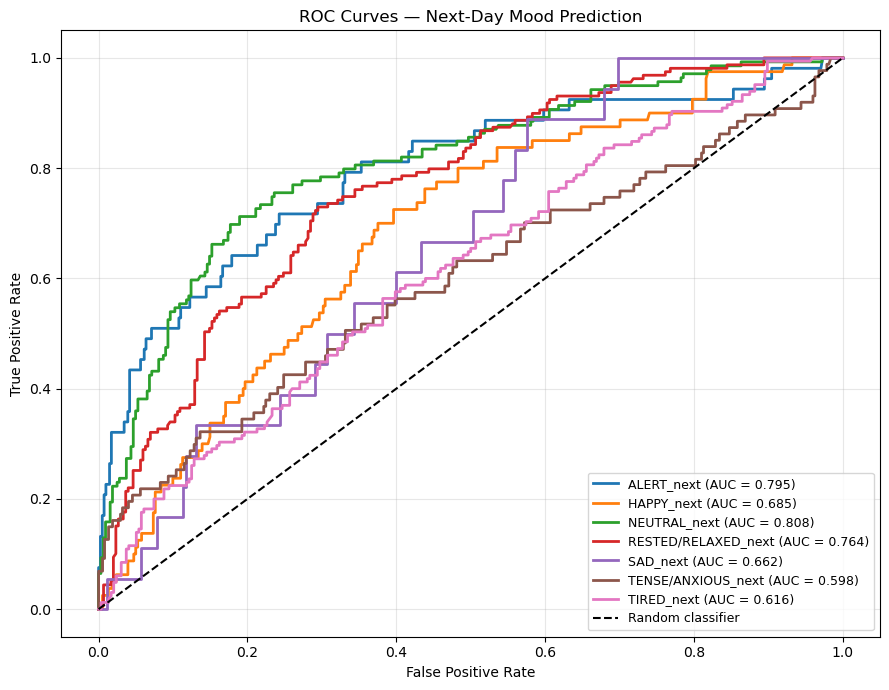

In [10]:



plt.figure(figsize=(9, 7))

for mood in next_cols:

    data = final_test_predictions_df[
        final_test_predictions_df["Mood"] == mood
    ]

    y_true = data["Actual"]
    probabilities = data["Probability"]

    # Calculate ROC curve
    fpr, tpr, _ = roc_curve(
        y_true, probabilities
    )

    auc = roc_auc_score(
        y_true, probabilities
    )

    
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{mood} (AUC = {auc:.3f})"
    )

# Random classifier 
plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Next-Day Mood Prediction")

plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()



plt.show()
